# Midnight Cart: The 2 AM Problem — Complete, Corrected Solution
**DSAI Challenge · IIT Roorkee × Masai · Campus Immersion 2026**

This notebook answers the four required questions: who cancels, when/where contribution is under pressure, whether cancellation can be predicted, and what Rohan should do.

**Important interpretation rules**
- `cancelled = 1` means cancelled; `0` means delivered.
- `margin_pct` is treated as the product-margin percentage supplied in the dataset.
- `basket_value_inr × margin_pct / 100 − discount_inr` is an **estimated contribution proxy before delivery/operating costs**, not audited net profit.
- Any policy-impact calculation is a scenario, not a causal guarantee. The dataset does not contain rider wages, picking costs, stockouts, or the counterfactual behaviour of customers after a policy change.
- The model only uses features plausibly available at checkout. `rating` and `refund_inr` are excluded because they may be known after the outcome.


In [1]:
# 1. Imports and reproducibility
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_STATE = 42


In [2]:
# 2. Load the dataset
# In Colab, upload midnight_cart_orders.csv if it is not already in the working directory.
candidate_paths = [
    "midnight_cart_orders.csv",
    "/mnt/data/files/midnight_cart_orders.csv",
    "/mnt/data/midnight_cart_orders.csv"
]
csv_file = next((p for p in candidate_paths if os.path.exists(p)), None)

if csv_file is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_file = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    except Exception:
        csv_file = None

if csv_file is None:
    raise FileNotFoundError(
        "Please place/upload midnight_cart_orders.csv in the notebook working directory and run this cell again."
    )

raw = pd.read_csv(csv_file)
print(f"Loaded: {csv_file}")
print(f"Raw rows: {len(raw):,} | Raw columns: {raw.shape[1]}")
display(raw.head())


Loaded: midnight_cart_orders.csv
Raw rows: 2,784 | Raw columns: 18


,order_id,order_datetime,hostel_zone,items_count,basket_value_inr,discount_inr,top_category,margin_pct,payment_mode,coupon_code,is_first_order,exam_week,rain_mm,riders_on_duty,eta_shown_min,cancelled,rating,refund_inr
0,MC-00001,2026-07-01 11:07:11,kaveri hstl,2,175,0,Snacks,10,UPI,NONE,N,N,3.6,4,15,0,5.0,0
1,MC-00002,2026-07-01 12:24:35,Kaveri Hstl,2,130,50,Drinks,11,Card,FIRST50,Y,N,6.3,6,8,0,4.0,0
2,MC-00003,01/07/2026 13:10,Yamuna Hostel,2,150,0,Stationery,23,Card,NONE,N,N,8.9,5,13,0,5.0,0
3,MC-00004,01/07/2026 13:41,Narmada Hostel,4,200,0,Drinks,14,Cash on delivery,NONE,N,N,0.0,4,17,0,3.0,0
4,MC-00005,2026-07-01 13:47:03,Narmada Hostel,3,210,0,Stationery,20,UPI,NONE,N,N,0.6,6,12,0,4.0,0


In [3]:
# 3. Initial data-quality audit
required_cols = [
    "order_id", "order_datetime", "hostel_zone", "items_count", "basket_value_inr",
    "discount_inr", "top_category", "margin_pct", "payment_mode", "coupon_code",
    "is_first_order", "exam_week", "rain_mm", "riders_on_duty", "eta_shown_min",
    "cancelled", "rating", "refund_inr"
]
missing_required = sorted(set(required_cols) - set(raw.columns))
if missing_required:
    raise ValueError(f"Required columns missing from the CSV: {missing_required}")

audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(dropna=True)
})
display(audit)

print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate order IDs:", int(raw["order_id"].duplicated().sum()))
print("Zero/negative basket values:", int((pd.to_numeric(raw["basket_value_inr"], errors="coerce") <= 0).sum()))
print("Negative discounts:", int((pd.to_numeric(raw["discount_inr"], errors="coerce") < 0).sum()))
print("Target values outside {0,1}:", int((~pd.to_numeric(raw["cancelled"], errors="coerce").isin([0, 1])).sum()))


,dtype,missing_count,missing_pct,unique_values
order_id,object,0,0.00,2700
order_datetime,object,0,0.00,2698
hostel_zone,object,0,0.00,25
items_count,int64,0,0.00,8
basket_value_inr,int64,0,0.00,157
discount_inr,int64,0,0.00,39
top_category,object,0,0.00,6
margin_pct,int64,0,0.00,36
payment_mode,object,0,0.00,3
coupon_code,object,0,0.00,3


Exact duplicate rows: 84
Duplicate order IDs: 84
Zero/negative basket values: 16
Negative discounts: 0
Target values outside {0,1}: 0


In [4]:
# 4. Clean and standardize
# Remove exact duplicate records first; preserve a count for the audit trail.
exact_duplicates_removed = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()

# Parse both date formats present in the source file.
date_text = df["order_datetime"].astype("string").str.strip()
dt_iso = pd.to_datetime(date_text, format="%Y-%m-%d %H:%M:%S", errors="coerce")
dt_dmy = pd.to_datetime(date_text, format="%d/%m/%Y %H:%M", errors="coerce")
df["order_dt"] = dt_iso.fillna(dt_dmy)

invalid_datetime_count = int(df["order_dt"].isna().sum())
invalid_target_count = int((~pd.to_numeric(df["cancelled"], errors="coerce").isin([0, 1])).sum())

# Coerce numeric fields; invalid strings become NaN and are handled in model pipelines where appropriate.
numeric_source_cols = [
    "items_count", "basket_value_inr", "discount_inr", "margin_pct",
    "rain_mm", "riders_on_duty", "eta_shown_min", "cancelled", "refund_inr"
]
for col in numeric_source_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Exclude rows where the timestamp or target is unusable.
before_invalid_filter = len(df)
df = df[df["order_dt"].notna() & df["cancelled"].isin([0, 1])].copy()
invalid_rows_removed = before_invalid_filter - len(df)

# Normalize category text.
text_cols = ["hostel_zone", "top_category", "payment_mode", "coupon_code", "is_first_order", "exam_week"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Normalize hostel-zone spelling variants without merging genuinely different areas.
zone_lower = (
    df["hostel_zone"].str.lower()
    .str.replace("hstl", "hostel", regex=False)
    .str.replace(r"\s+", " ", regex=True)
)
zone_map = {
    "kaveri hostel": "Kaveri Hostel",
    "yamuna hostel": "Yamuna Hostel",
    "narmada hostel": "Narmada Hostel",
    "ganga hostel": "Ganga Hostel",
    "faculty colny": "Faculty Colony",
    "faculty colony": "Faculty Colony",
    "market rd pgs": "Market Road PGs",
    "market road pgs": "Market Road PGs",
    "market road pg": "Market Road PGs",
}
df["hostel_zone"] = zone_lower.map(zone_map).fillna(zone_lower.str.title())

# The source contains zero-value baskets. They are anomalous for contribution analysis;
# exclude them from financial analysis/modeling and report how many were excluded.
zero_basket_count = int((df["basket_value_inr"] <= 0).sum())
df = df[df["basket_value_inr"] > 0].copy()

# Extract hour from the parsed timestamp. The operating day can extend past midnight;
# exam_week is already supplied by the dataset, so do not recalculate it from calendar date.
df["hour"] = df["order_dt"].dt.hour
df["cancelled"] = df["cancelled"].astype(int)
df = df.sort_values("order_dt").reset_index(drop=True)

cleaning_summary = pd.DataFrame({
    "Check / action": [
        "Raw rows",
        "Exact duplicate rows removed",
        "Rows removed for invalid timestamp/target",
        "Zero/negative basket rows excluded",
        "Final analysis rows",
        "Unparseable timestamps remaining",
        "Duplicate order IDs remaining",
        "Missing ratings (expected post-order field)"
    ],
    "Count": [
        len(raw), exact_duplicates_removed, invalid_rows_removed, zero_basket_count,
        len(df), int(df["order_dt"].isna().sum()), int(df["order_id"].duplicated().sum()),
        int(df["rating"].isna().sum())
    ]
})
display(cleaning_summary)
print(f"Cleaned date range: {df['order_dt'].min()} to {df['order_dt'].max()}")
print(f"Overall cancellation rate: {df['cancelled'].mean():.1%} ({df['cancelled'].sum():,} cancellations / {len(df):,} orders)")


,Check / action,Count
0,Raw rows,2784
1,Exact duplicate rows removed,84
2,Rows removed for invalid timestamp/target,0
3,Zero/negative basket rows excluded,15
4,Final analysis rows,2685
5,Unparseable timestamps remaining,0
6,Duplicate order IDs remaining,0
7,Missing ratings (expected post-order field),394


Cleaned date range: 2026-07-01 11:07:11 to 2026-09-29 01:55:00
Overall cancellation rate: 14.7% (394 cancellations / 2,685 orders)


## Slide 1 takeaway — Data quality

The file contains duplicate rows, mixed timestamp formats, spelling variants in hostel zones, and zero-value baskets. The cleaning steps above show the counts rather than making unverified claims. Missing `rating` values are expected because ratings may only exist for some completed orders; they are not imputed for the cancellation model.

In [5]:
# 5. Helper functions and contribution proxy
def rate_table(data, group_col):
    out = data.groupby(group_col, dropna=False).agg(
        orders=("order_id", "size"),
        cancellations=("cancelled", "sum"),
        cancellation_rate=("cancelled", "mean")
    ).reset_index()
    out["cancellation_rate_pct"] = (out["cancellation_rate"] * 100).round(1)
    return out.drop(columns="cancellation_rate").sort_values("cancellation_rate_pct", ascending=False)

# This is a contribution proxy only. It excludes delivery labour, picking/packing, spoilage,
# payment fees and other costs; do not call it audited net profit.
df["gross_product_margin_inr"] = df["basket_value_inr"] * df["margin_pct"] / 100
df["contribution_proxy_inr"] = df["gross_product_margin_inr"] - df["discount_inr"]

print("Contribution proxy = basket value × margin_pct / 100 − coupon discount")
print("Use delivered orders for observed sale contribution; cancelled-order contribution is not treated as realized sales.")


Contribution proxy = basket value × margin_pct / 100 − coupon discount
Use delivered orders for observed sale contribution; cancelled-order contribution is not treated as realized sales.


,hour,orders,cancellations,cancellation_rate,cancellation_rate_pct
0,0,139,35,0.252,25.180
1,1,74,9,0.122,12.162
2,10,68,8,0.118,11.765
3,11,71,11,0.155,15.493
4,12,127,14,0.110,11.024
5,13,149,12,0.081,8.054
6,14,77,13,0.169,16.883
7,15,83,12,0.145,14.458
8,16,115,18,0.157,15.652
9,17,165,22,0.133,13.333


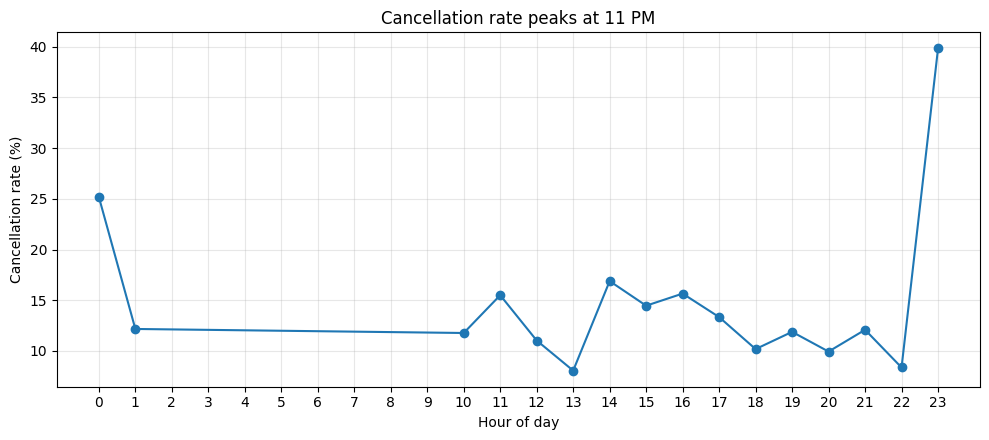

23:00 — 96/241 cancelled (39.8%).
00:00 — 35/139 cancelled (25.2%).


In [6]:
# 6. Insight A — cancellation by hour
hourly = df.groupby("hour").agg(
    orders=("order_id", "size"),
    cancellations=("cancelled", "sum"),
    cancellation_rate=("cancelled", "mean")
).reset_index()
hourly["cancellation_rate_pct"] = hourly["cancellation_rate"] * 100
display(hourly.round(3))

plt.figure(figsize=(10, 4.5))
plt.plot(hourly["hour"], hourly["cancellation_rate_pct"], marker="o")
plt.xticks(range(0, 24))
plt.xlabel("Hour of day")
plt.ylabel("Cancellation rate (%)")
plt.title("Cancellation rate peaks at 11 PM")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

peak_23 = hourly.loc[hourly["hour"] == 23].iloc[0]
midnight = hourly.loc[hourly["hour"] == 0].iloc[0]
print(f"23:00 — {int(peak_23['cancellations'])}/{int(peak_23['orders'])} cancelled ({peak_23['cancellation_rate_pct']:.1f}%).")
print(f"00:00 — {int(midnight['cancellations'])}/{int(midnight['orders'])} cancelled ({midnight['cancellation_rate_pct']:.1f}%).")


,eta_band,orders,cancellations,cancellation_rate,cancellation_rate_pct
0,≤10 min,427,50,0.117,11.710
1,11–15 min,1682,180,0.107,10.702
2,16–20 min,461,90,0.195,19.523
3,>20 min,115,74,0.643,64.348


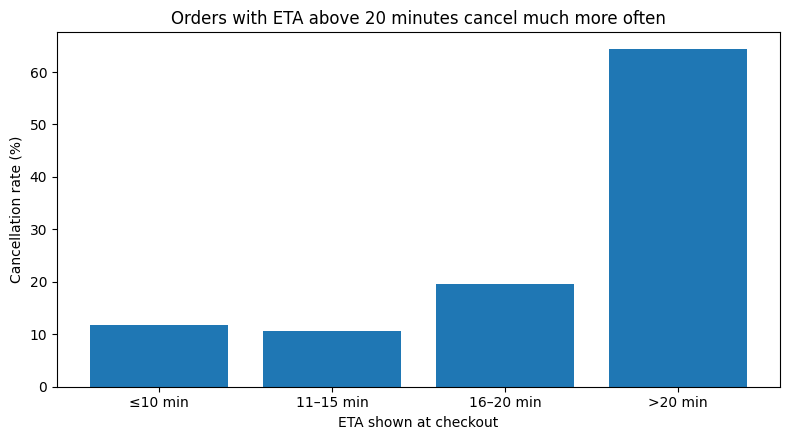

In [7]:
# 7. Insight B — ETA bands
df["eta_band"] = pd.cut(
    df["eta_shown_min"],
    bins=[-np.inf, 10, 15, 20, np.inf],
    labels=["≤10 min", "11–15 min", "16–20 min", ">20 min"],
    right=True
)
eta_summary = df.groupby("eta_band", observed=True).agg(
    orders=("order_id", "size"),
    cancellations=("cancelled", "sum"),
    cancellation_rate=("cancelled", "mean")
).reset_index()
eta_summary["cancellation_rate_pct"] = eta_summary["cancellation_rate"] * 100
display(eta_summary.round(3))

plt.figure(figsize=(8, 4.5))
plt.bar(eta_summary["eta_band"].astype(str), eta_summary["cancellation_rate_pct"])
plt.xlabel("ETA shown at checkout")
plt.ylabel("Cancellation rate (%)")
plt.title("Orders with ETA above 20 minutes cancel much more often")
plt.tight_layout()
plt.show()


In [8]:
# 8. Insight C — coupon, payment, exam week, first order, zone and category
for col in ["coupon_code", "payment_mode", "exam_week", "is_first_order", "hostel_zone", "top_category"]:
    print(f"\nCancellation rate by {col}")
    display(rate_table(df, col).round(3))

# Compact comparison for the presentation
comparisons = {
    "FIRST50": df[df["coupon_code"] == "FIRST50"],
    "No coupon": df[df["coupon_code"] == "NONE"],
    "Exam week": df[df["exam_week"] == "Y"],
    "Non-exam week": df[df["exam_week"] == "N"],
    "First order": df[df["is_first_order"] == "Y"],
    "Repeat order": df[df["is_first_order"] == "N"],
    "Cash on delivery": df[df["payment_mode"] == "Cash on delivery"],
    "Card": df[df["payment_mode"] == "Card"],
}
for name, subset in comparisons.items():
    print(f"{name}: {len(subset)} orders; cancellation rate {subset['cancelled'].mean():.1%}")



Cancellation rate by coupon_code


,coupon_code,orders,cancellations,cancellation_rate_pct
1,FIRST50,354,112,31.6
0,EXAM20,101,16,15.8
2,NONE,2230,266,11.9



Cancellation rate by payment_mode


,payment_mode,orders,cancellations,cancellation_rate_pct
1,Cash on delivery,684,160,23.4
2,UPI,1626,204,12.5
0,Card,375,30,8.0



Cancellation rate by exam_week


...


Cancellation rate by hostel_zone


,hostel_zone,orders,cancellations,cancellation_rate_pct
3,Market Road PGs,362,77,21.3
5,Yamuna Hostel,537,85,15.8
2,Kaveri Hostel,505,75,14.9
4,Narmada Hostel,451,63,14.0
1,Ganga Hostel,606,76,12.5
0,Faculty Colony,224,18,8.0



Cancellation rate by top_category


,top_category,orders,cancellations,cancellation_rate_pct
1,Electronics,232,39,16.8
5,Stationery,227,37,16.3
3,Instant food,563,88,15.6
4,Snacks,848,131,15.4
0,Drinks,572,73,12.8
2,Health,243,26,10.7


FIRST50: 354 orders; cancellation rate 31.6%
No coupon: 2230 orders; cancellation rate 11.9%
Exam week: 480 orders; cancellation rate 25.0%
Non-exam week: 2205 orders; cancellation rate 12.4%
First order: 494 orders; cancellation rate 26.9%
Repeat order: 2191 orders; cancellation rate 11.9%
Cash on delivery: 684 orders; cancellation rate 23.4%
Card: 375 orders; cancellation rate 8.0%


In [9]:
# 9. Contribution proxy by coupon — show all orders and delivered orders separately
coupon_all = df.groupby("coupon_code").agg(
    orders=("order_id", "size"),
    cancellations=("cancelled", "sum"),
    cancellation_rate=("cancelled", "mean"),
    avg_basket_inr=("basket_value_inr", "mean"),
    avg_discount_inr=("discount_inr", "mean"),
    total_discount_inr=("discount_inr", "sum"),
    avg_contribution_proxy_inr=("contribution_proxy_inr", "mean"),
    total_contribution_proxy_inr=("contribution_proxy_inr", "sum")
).reset_index()

delivered = df[df["cancelled"] == 0].copy()
coupon_delivered = delivered.groupby("coupon_code").agg(
    delivered_orders=("order_id", "size"),
    avg_discount_inr=("discount_inr", "mean"),
    total_discount_inr=("discount_inr", "sum"),
    avg_contribution_proxy_inr=("contribution_proxy_inr", "mean"),
    total_contribution_proxy_inr=("contribution_proxy_inr", "sum")
).reset_index()

print("All-order descriptive table (not a realized-profit table):")
display(coupon_all.round(2))
print("Delivered-order contribution proxy:")
display(coupon_delivered.round(2))

first50_delivered = delivered[delivered["coupon_code"] == "FIRST50"]
first50_avg_proxy = first50_delivered["contribution_proxy_inr"].mean()
first50_total_proxy = first50_delivered["contribution_proxy_inr"].sum()
first50_delivered_discount = first50_delivered["discount_inr"].sum()

exam20_outside = df[(df["coupon_code"] == "EXAM20") & (df["exam_week"] == "N")]
exam20_outside_count = len(exam20_outside)
exam20_outside_discount = exam20_outside["discount_inr"].sum()

print(f"Delivered FIRST50 orders: {len(first50_delivered)}")
print(f"Average contribution proxy per delivered FIRST50 order: ₹{first50_avg_proxy:,.2f}")
print(f"Total contribution proxy across delivered FIRST50 orders: ₹{first50_total_proxy:,.2f}")
print(f"Discount applied to delivered FIRST50 orders: ₹{first50_delivered_discount:,.0f}")
print(f"EXAM20 orders outside exam week: {exam20_outside_count}; discounts on those orders: ₹{exam20_outside_discount:,.0f}")
print("Caution: EXAM20 is only 'outside-policy' if the business intended it to be exam-week-only; the CSV description alone does not prove that rule.")


All-order descriptive table (not a realized-profit table):


,coupon_code,orders,cancellations,cancellation_rate,avg_basket_inr,avg_discount_inr,total_discount_inr,avg_contribution_proxy_inr,total_contribution_proxy_inr
0,EXAM20,101,16,0.16,252.62,39.38,3977,6.37,643.3
1,FIRST50,354,112,0.32,189.68,49.80,17630,-18.50,-6547.3
2,NONE,2230,266,0.12,250.62,0.00,0,42.31,94341.7


Delivered-order contribution proxy:


,coupon_code,delivered_orders,avg_discount_inr,total_discount_inr,avg_contribution_proxy_inr,total_contribution_proxy_inr
0,EXAM20,85,40.47,3440,9.39,798.30
1,FIRST50,242,49.81,12055,-18.95,-4586.75
2,NONE,1964,0.00,0,41.74,81971.05


Delivered FIRST50 orders: 242
Average contribution proxy per delivered FIRST50 order: ₹-18.95
Total contribution proxy across delivered FIRST50 orders: ₹-4,586.75
Discount applied to delivered FIRST50 orders: ₹12,055
EXAM20 orders outside exam week: 52; discounts on those orders: ₹2,171
Caution: EXAM20 is only 'outside-policy' if the business intended it to be exam-week-only; the CSV description alone does not prove that rule.


In [10]:
# 10. Late-night diagnosis: 11 PM through 1:59 AM (hours 23, 0, 1)
late = df[df["hour"].isin([23, 0, 1])].copy()
late_payment = late.groupby("payment_mode").agg(
    orders=("order_id", "size"),
    cancellations=("cancelled", "sum"),
    cancellation_rate=("cancelled", "mean")
).reset_index()
late_payment["cancellation_rate_pct"] = late_payment["cancellation_rate"] * 100
display(late_payment.round(3))

late_cod = late[late["payment_mode"] == "Cash on delivery"]
late_card = late[late["payment_mode"] == "Card"]
late_cod_n = len(late_cod)
late_cod_cancels = int(late_cod["cancelled"].sum())
late_cod_rate = late_cod["cancelled"].mean()
late_card_rate = late_card["cancelled"].mean()
late_cod_delivered = late_cod[late_cod["cancelled"] == 0]
late_cod_avg_proxy = late_cod_delivered["contribution_proxy_inr"].mean()

print(f"Late-night COD: {late_cod_cancels}/{late_cod_n} cancelled ({late_cod_rate:.1%}).")
print(f"Late-night Card: {int(late_card['cancelled'].sum())}/{len(late_card)} cancelled ({late_card_rate:.1%}).")
print("Association is not proof that COD causes cancellation; a payment-policy change should be tested.")


,payment_mode,orders,cancellations,cancellation_rate,cancellation_rate_pct
0,Card,57,10,0.175,17.544
1,Cash on delivery,115,48,0.417,41.739
2,UPI,282,82,0.291,29.078


Late-night COD: 48/115 cancelled (41.7%).
Late-night Card: 10/57 cancelled (17.5%).
Association is not proof that COD causes cancellation; a payment-policy change should be tested.


,Metric,Value
0,Train rows (earlier dates),2013.0000
1,Test rows (later dates),672.0000
2,Test cancellation prevalence,0.1845
3,Precision at 0.50 threshold,0.3660
4,Recall at 0.50 threshold,0.7823
5,F1 at 0.50 threshold,0.4987
6,ROC-AUC,0.8117
7,Average precision (PR-AUC summary),0.5954
8,Balanced accuracy,0.7378


              precision    recall  f1-score   support

           0      0.934     0.693     0.796       548
           1      0.366     0.782     0.499       124

    accuracy                          0.710       672
   macro avg      0.650     0.738     0.647       672
weighted avg      0.829     0.710     0.741       672



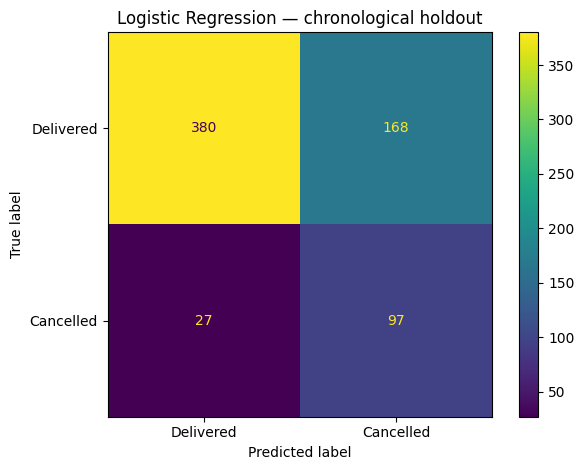

In [11]:
# 11. Logistic Regression — chronological holdout to mimic future prediction
# Only include features plausibly available at checkout. Exclude rating/refund and outcome-derived fields.
numeric_features = [
    "items_count", "basket_value_inr", "discount_inr",
    "rain_mm", "riders_on_duty", "eta_shown_min", "hour"
]
categorical_features = [
    "hostel_zone", "top_category", "payment_mode",
    "coupon_code", "is_first_order", "exam_week"
]
feature_cols = numeric_features + categorical_features

model_data = df.sort_values("order_dt").reset_index(drop=True).copy()
split_idx = int(len(model_data) * 0.75)
train_df = model_data.iloc[:split_idx].copy()
test_df = model_data.iloc[split_idx:].copy()

X_train, y_train = train_df[feature_cols], train_df["cancelled"]
X_test, y_test = test_df[feature_cols], test_df["cancelled"]

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)  # default 0.50 threshold
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Train rows (earlier dates)": len(train_df),
    "Test rows (later dates)": len(test_df),
    "Test cancellation prevalence": round(float(y_test.mean()), 4),
    "Precision at 0.50 threshold": round(float(precision_score(y_test, y_pred, zero_division=0)), 4),
    "Recall at 0.50 threshold": round(float(recall_score(y_test, y_pred, zero_division=0)), 4),
    "F1 at 0.50 threshold": round(float(f1_score(y_test, y_pred, zero_division=0)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_prob)), 4),
    "Average precision (PR-AUC summary)": round(float(average_precision_score(y_test, y_prob)), 4),
    "Balanced accuracy": round(float(balanced_accuracy_score(y_test, y_pred)), 4)
}
display(pd.DataFrame({"Metric": list(metrics.keys()), "Value": list(metrics.values())}))
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Delivered", "Cancelled"]).plot()
plt.title("Logistic Regression — chronological holdout")
plt.tight_layout()
plt.show()


In [12]:
# 12. Interpret model coefficients cautiously
# Numeric features were standardized; categorical features are one-hot encoded with a reference category.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coef_values = model.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coef_values})
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
coef_table = coef_table.sort_values("abs_coefficient", ascending=False)

print("Largest absolute coefficients (association in this fitted model, not causation):")
display(coef_table.head(12).round(3))

print("Reference note: coefficients are log-odds effects relative to encoded reference categories; standardized numeric coefficients are not directly comparable to unscaled raw-unit coefficients.")


Largest absolute coefficients (association in this fitted model, not causation):


,feature,coefficient,abs_coefficient
17,cat__payment_mode_Cash on delivery,1.237,1.237
9,cat__hostel_zone_Market Road PGs,1.170,1.170
11,cat__hostel_zone_Yamuna Hostel,0.772,0.772
10,cat__hostel_zone_Narmada Hostel,0.663,0.663
7,cat__hostel_zone_Ganga Hostel,0.574,0.574
19,cat__coupon_code_FIRST50,0.558,0.558
21,cat__is_first_order_Y,0.542,0.542
8,cat__hostel_zone_Kaveri Hostel,0.519,0.519
18,cat__payment_mode_UPI,0.426,0.426
5,num__eta_shown_min,0.423,0.423


Reference note: coefficients are log-odds effects relative to encoded reference categories; standardized numeric coefficients are not directly comparable to unscaled raw-unit coefficients.


In [13]:
# 13. Three decision options with transparent, scenario-based ₹ calculations
# Option 1: Coupon policy. This is the strongest data-backed candidate because the delivered FIRST50
# contribution proxy is negative. Any change still requires a demand/retention test.
first50_below_300 = first50_delivered[first50_delivered["basket_value_inr"] < 300]
coupon_discount_upper_bound = float(first50_below_300["discount_inr"].sum())
coupon_orders_below_300 = len(first50_below_300)

# Option 2: Late-night COD trial. Scenario: if late-night COD cancellation rate fell to the observed
# late-night Card cancellation rate while order volume stayed constant.
expected_cod_cancels_at_card_rate = late_cod_n * late_card_rate
scenario_cancels_avoided = max(0.0, late_cod_cancels - expected_cod_cancels_at_card_rate)
cod_scenario_contribution = scenario_cancels_avoided * float(late_cod_avg_proxy if pd.notna(late_cod_avg_proxy) else 0.0)

# Option 3: Night dispatch / pick-pack pilot for late-night Stationery and Snacks.
# Scenario: category cancellation rates fall to the overall late-night cancellation rate.
late_rate = float(late["cancelled"].mean())
late_focus = late[late["top_category"].isin(["Stationery", "Snacks"])]
focus_summary = late_focus.groupby("top_category").agg(
    orders=("order_id", "size"),
    cancellations=("cancelled", "sum")
)
delivered_focus = late_focus[late_focus["cancelled"] == 0].groupby("top_category")["contribution_proxy_inr"].mean()
focus_avoided = 0.0
focus_value = 0.0
for category, row in focus_summary.iterrows():
    expected_cancels = row["orders"] * late_rate
    focus_avoided += max(0.0, float(row["cancellations"] - expected_cancels))
    avg_proxy = float(delivered_focus.get(category, 0.0))
    focus_value += max(0.0, float(row["cancellations"] - expected_cancels)) * avg_proxy

recommendations = pd.DataFrame([
    {
        "Option": "1. Coupon policy (recommended primary test)",
        "Action": "Pilot a minimum basket for FIRST50; review promo eligibility and retain customers who still convert.",
        "Observed evidence": f"{len(first50_delivered)} delivered FIRST50 orders; average contribution proxy ₹{first50_avg_proxy:.2f}/order.",
        "₹ estimate / scenario": f"₹{coupon_discount_upper_bound:,.0f} is the upper-bound discount on {coupon_orders_below_300} delivered FIRST50 orders with baskets below ₹300, if those same orders still occurred without the coupon.",
        "Caveat": "Not a forecast or guaranteed saving; customers may abandon or change basket size. Contribution proxy excludes delivery/operating costs."
    },
    {
        "Option": "2. Late-night COD policy trial",
        "Action": "Run a limited 11 PM–2 AM prepaid-payment experiment; compare conversion and cancellation with a control group.",
        "Observed evidence": f"{late_cod_cancels}/{late_cod_n} late-night COD orders cancelled ({late_cod_rate:.1%}) vs {late_card_rate:.1%} for Card.",
        "₹ estimate / scenario": f"If COD cancellation rate fell to the observed Card rate with order volume unchanged, about {scenario_cancels_avoided:.1f} cancellations would be avoided; at ₹{late_cod_avg_proxy:.2f} contribution proxy per delivered late-night COD order, scenario value ≈ ₹{cod_scenario_contribution:,.0f}.",
        "Caveat": "Observational comparison, not causal proof; customer conversion may fall. Rider cost data is unavailable."
    },
    {
        "Option": "3. Night dispatch / pick-pack pilot",
        "Action": "Audit late-night pick/pack and dispatch for Stationery and Snacks; do not hide these products based on cancellation rate alone.",
        "Observed evidence": f"Late-night Stationery cancellation rate {late[late['top_category']=='Stationery']['cancelled'].mean():.1%}; Snacks {late[late['top_category']=='Snacks']['cancelled'].mean():.1%}; overall late-night {late_rate:.1%}.",
        "₹ estimate / scenario": f"If both category cancellation rates fell to the overall late-night rate, roughly {focus_avoided:.1f} cancellations might be avoided; proxy contribution scenario ≈ ₹{focus_value:,.0f}.",
        "Caveat": "No stockout or pick-time fields are available, so the dataset cannot prove inventory is the cause. Treat as a small operational pilot."
    }
])
display(recommendations)
print("Primary recommendation: test coupon economics first, because FIRST50's delivered-order contribution proxy is negative in the observed data.")
print("Rohan can only make one major change next month: treat Options 2 and 3 as alternatives/pilots, not simultaneous major changes.")


,Option,Action,Observed evidence,₹ estimate / scenario,Caveat
0,1. Coupon policy (recommended primary test),Pilot a minimum basket for FIRST50; review pro...,242 delivered FIRST50 orders; average contribu...,"₹10,355 is the upper-bound discount on 208 del...",Not a forecast or guaranteed saving; customers...
1,2. Late-night COD policy trial,Run a limited 11 PM–2 AM prepaid-payment exper...,48/115 late-night COD orders cancelled (41.7%)...,If COD cancellation rate fell to the observed ...,"Observational comparison, not causal proof; cu..."
2,3. Night dispatch / pick-pack pilot,Audit late-night pick/pack and dispatch for St...,Late-night Stationery cancellation rate 53.8%;...,If both category cancellation rates fell to th...,"No stockout or pick-time fields are available,..."


Primary recommendation: test coupon economics first, because FIRST50's delivered-order contribution proxy is negative in the observed data.
Rohan can only make one major change next month: treat Options 2 and 3 as alternatives/pilots, not simultaneous major changes.


## 14. SQL analysis with SQLite — additional checks from the companion notebook

This section keeps the main solution's cleaning, chronological split, and leakage controls. It uses SQLite queries on the already-cleaned `df` so the SQL results align with the primary analysis. Run after Sections 1–13.

**Why SQL here?** It demonstrates how an analyst can answer business questions using `GROUP BY`, conditional aggregation, and `CASE WHEN`, then use Python charts to communicate the results. SQL is an additional analysis layer—not a second cleaning pipeline.

In [14]:
# Load the cleaned analysis frame into an in-memory SQLite table.
import sqlite3

sql_conn = sqlite3.connect(':memory:')
sql_df = df.copy()
# SQLite does not need pandas' timezone-aware datetime for these queries; hour is already extracted.
sql_df.to_sql('orders', sql_conn, if_exists='replace', index=False)

print(f'SQL table ready: {len(sql_df):,} cleaned orders, {sql_df.shape[1]} columns.')
print('All SQL summaries below use the cleaned analysis population, not the raw CSV.')

SQL table ready: 2,685 cleaned orders, 23 columns.
All SQL summaries below use the cleaned analysis population, not the raw CSV.


In [15]:
# SQL 1 — cancellation rate and rider coverage by hour.
sql_hourly = pd.read_sql_query('''
SELECT
  hour,
  COUNT(*) AS orders,
  SUM(cancelled) AS cancellations,
  ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct,
  ROUND(AVG(riders_on_duty), 2) AS avg_riders_on_duty,
  ROUND(AVG(eta_shown_min), 1) AS avg_eta_min
FROM orders
GROUP BY hour
ORDER BY hour
''', sql_conn)
display(sql_hourly)

# SQL 2 — 12 AM–2 AM window (hours 0 and 1), split by exam-week flag.
sql_exam_midnight = pd.read_sql_query('''
SELECT
  CASE WHEN hour IN (0, 1) THEN '12 AM–2 AM' ELSE 'Other hours' END AS time_window,
  exam_week,
  COUNT(*) AS orders,
  SUM(cancelled) AS cancellations,
  ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct
FROM orders
WHERE hour IN (0, 1)
GROUP BY exam_week
ORDER BY exam_week
''', sql_conn)
display(sql_exam_midnight)

# SQL 3 — FIRST50 versus no coupon by basket-size band.
sql_first50_basket = pd.read_sql_query('''
SELECT
  coupon_code,
  CASE
    WHEN items_count = 1 THEN '1 item'
    WHEN items_count BETWEEN 2 AND 3 THEN '2–3 items'
    WHEN items_count >= 4 THEN '4+ items'
    ELSE 'Unknown items'
  END AS basket_size_band,
  COUNT(*) AS orders,
  SUM(cancelled) AS cancellations,
  ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct,
  ROUND(AVG(basket_value_inr), 2) AS avg_basket_inr,
  ROUND(AVG(discount_inr), 2) AS avg_discount_inr
FROM orders
WHERE coupon_code IN ('FIRST50', 'NONE')
GROUP BY coupon_code, basket_size_band
ORDER BY coupon_code, CASE basket_size_band WHEN '1 item' THEN 1 WHEN '2–3 items' THEN 2 WHEN '4+ items' THEN 3 ELSE 4 END
''', sql_conn)
display(sql_first50_basket)

# SQL 4 — coupon-level outcomes and delivered-order contribution proxy.
sql_coupon = pd.read_sql_query('''
SELECT
  coupon_code,
  COUNT(*) AS orders,
  SUM(cancelled) AS cancellations,
  ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct,
  ROUND(SUM(CASE WHEN cancelled = 0 THEN contribution_proxy_inr ELSE 0 END), 2) AS delivered_contribution_proxy_inr,
  ROUND(SUM(CASE WHEN cancelled = 0 THEN discount_inr ELSE 0 END), 2) AS delivered_discount_inr
FROM orders
GROUP BY coupon_code
ORDER BY cancellation_rate_pct DESC
''', sql_conn)
display(sql_coupon)

,hour,orders,cancellations,cancellation_rate_pct,avg_riders_on_duty,avg_eta_min
0,0,139,35,25.2,4.00,16.0
1,1,74,9,12.2,3.80,11.5
2,10,68,8,11.8,4.06,10.3
3,11,71,11,15.5,4.01,10.6
4,12,127,14,11.0,5.06,11.6
5,13,149,12,8.1,5.05,12.9
6,14,77,13,16.9,5.04,10.4
7,15,83,12,14.5,4.95,11.1
8,16,115,18,15.7,4.97,11.7
9,17,165,22,13.3,5.05,12.8


,time_window,exam_week,orders,cancellations,cancellation_rate_pct
0,12 AM–2 AM,N,148,22,14.9
1,12 AM–2 AM,Y,65,22,33.8


,coupon_code,basket_size_band,orders,cancellations,cancellation_rate_pct,avg_basket_inr,avg_discount_inr
0,FIRST50,1 item,89,33,37.1,139.61,49.21
1,FIRST50,2–3 items,192,61,31.8,173.70,50.00
2,FIRST50,4+ items,73,18,24.7,292.74,50.00
3,NONE,1 item,643,70,10.9,171.88,0.00
4,NONE,2–3 items,1168,149,12.8,243.72,0.00
5,NONE,4+ items,419,47,11.2,390.69,0.00


,coupon_code,orders,cancellations,cancellation_rate_pct,delivered_contribution_proxy_inr,delivered_discount_inr
0,FIRST50,354,112,31.6,-4586.75,12055.0
1,EXAM20,101,16,15.8,798.30,3440.0
2,NONE,2230,266,11.9,81971.05,0.0


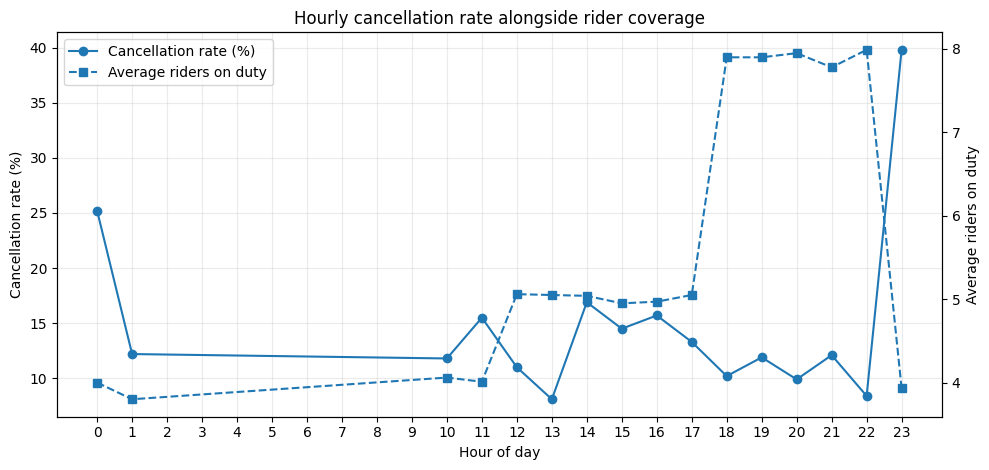

Interpretation: a pattern can help prioritize an operations audit, but this observational chart cannot prove rider staffing caused cancellations.


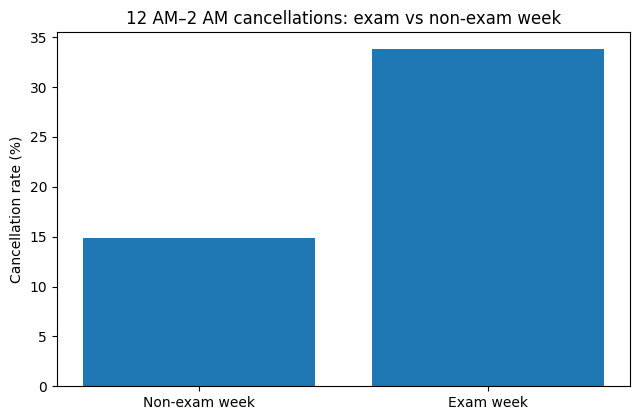

,exam_label,orders,cancellations,cancellation_rate_pct
0,Non-exam week,148,22,14.9
1,Exam week,65,22,33.8


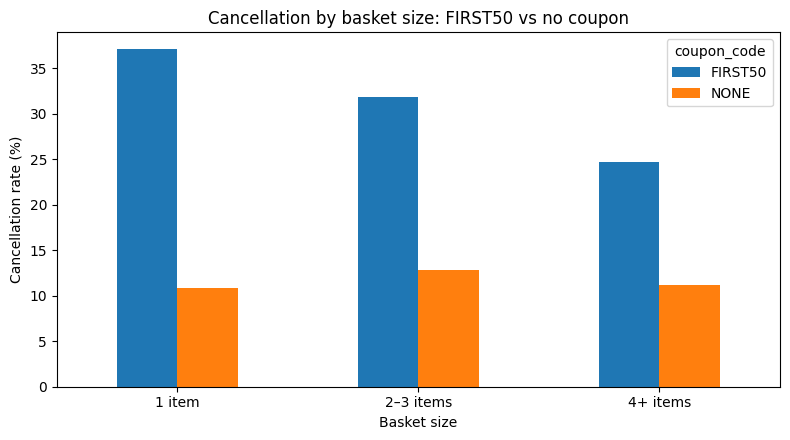

Read each bar with its order count from sql_first50_basket; small groups can produce volatile rates.


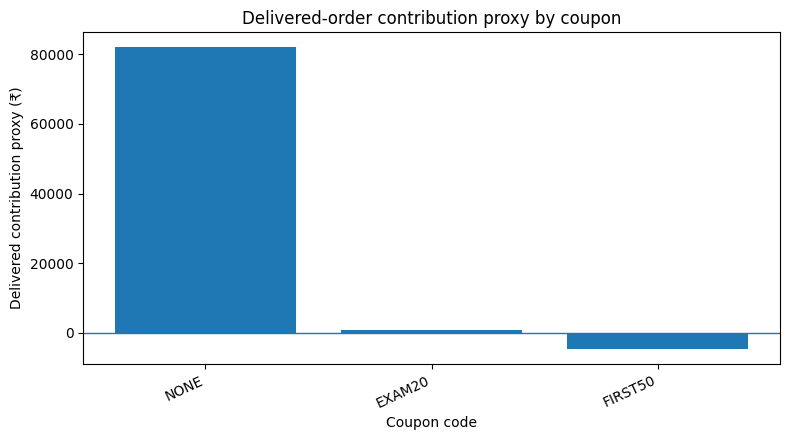

Contribution proxy = basket value × margin_pct / 100 − discount. It excludes delivery labour, pick/pack, spoilage, payment fees, and other operating costs.


In [16]:
# Extra chart 1 — cancellation and rider coverage by hour.
fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.plot(sql_hourly['hour'], sql_hourly['cancellation_rate_pct'], marker='o', label='Cancellation rate (%)')
ax1.set_xlabel('Hour of day')
ax1.set_ylabel('Cancellation rate (%)')
ax1.set_xticks(range(24))
ax1.grid(True, alpha=0.25)
ax2 = ax1.twinx()
ax2.plot(sql_hourly['hour'], sql_hourly['avg_riders_on_duty'], marker='s', linestyle='--', label='Average riders on duty')
ax2.set_ylabel('Average riders on duty')
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc='upper left')
plt.title('Hourly cancellation rate alongside rider coverage')
plt.tight_layout()
plt.show()
print('Interpretation: a pattern can help prioritize an operations audit, but this observational chart cannot prove rider staffing caused cancellations.')

# Extra chart 2 — compare midnight cancellation rates by exam-week flag.
if not sql_exam_midnight.empty:
    plot_exam = sql_exam_midnight.copy()
    plot_exam['exam_label'] = plot_exam['exam_week'].map({'Y': 'Exam week', 'N': 'Non-exam week'}).fillna(plot_exam['exam_week'].astype(str))
    plt.figure(figsize=(6.5, 4.3))
    plt.bar(plot_exam['exam_label'], plot_exam['cancellation_rate_pct'])
    plt.ylabel('Cancellation rate (%)')
    plt.title('12 AM–2 AM cancellations: exam vs non-exam week')
    plt.tight_layout()
    plt.show()
    display(plot_exam[['exam_label', 'orders', 'cancellations', 'cancellation_rate_pct']])

# Extra chart 3 — FIRST50 vs no coupon, cancellation rate by basket-size band.
plot_basket = sql_first50_basket[sql_first50_basket['coupon_code'].isin(['FIRST50', 'NONE'])].copy()
if not plot_basket.empty:
    pivot_basket = plot_basket.pivot(index='basket_size_band', columns='coupon_code', values='cancellation_rate_pct')
    pivot_basket = pivot_basket.reindex([x for x in ['1 item', '2–3 items', '4+ items'] if x in pivot_basket.index])
    ax = pivot_basket.plot(kind='bar', figsize=(8, 4.5))
    ax.set_xlabel('Basket size')
    ax.set_ylabel('Cancellation rate (%)')
    ax.set_title('Cancellation by basket size: FIRST50 vs no coupon')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print('Read each bar with its order count from sql_first50_basket; small groups can produce volatile rates.')

# Extra chart 4 — delivered contribution proxy by coupon (not audited net profit).
plot_coupon = sql_coupon.sort_values('delivered_contribution_proxy_inr', ascending=False)
plt.figure(figsize=(8, 4.5))
plt.bar(plot_coupon['coupon_code'].astype(str), plot_coupon['delivered_contribution_proxy_inr'])
plt.axhline(0, linewidth=1)
plt.xlabel('Coupon code')
plt.ylabel('Delivered contribution proxy (₹)')
plt.title('Delivered-order contribution proxy by coupon')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()
print('Contribution proxy = basket value × margin_pct / 100 − discount. It excludes delivery labour, pick/pack, spoilage, payment fees, and other operating costs.')

### SQL findings: how to use them responsibly

- Use the hour-level query to identify **when** cancellation risk and rider coverage move together; investigate rather than assuming causation.
- Use the midnight exam-week query to test whether late-night demand behaves differently during exams. The query is restricted to hours 0 and 1, so it is not the same as the wider 11 PM–2 AM operational window used elsewhere.
- Use the FIRST50 basket-size comparison to see whether coupon-associated cancellation varies with basket size. Always show denominators and avoid claiming the coupon caused the difference.
- Use the coupon contribution chart to discuss delivered-order economics. The value is a **contribution proxy**, not net profit or guaranteed savings.
- The primary model remains the chronological train/test split with preprocessing in a pipeline. Do not replace it with a random split just to improve scores; the metrics are meant to approximate future performance.

## Final executive summary (for the 5-slide presentation)

1. **Data quality:** 2,784 raw rows; 84 exact duplicate rows removed; mixed timestamp formats parsed; hostel-zone variants standardized; zero-value baskets excluded from contribution/model analysis.
2. **Peak risk:** 11 PM has 96 cancellations among 241 orders (**39.8%**); ETA above 20 minutes has 74 cancellations among 115 orders (**64.3%**).
3. **Customer/offer signals:** FIRST50 cancellation rate is **31.6%** (112/354) vs **11.9%** without a coupon (266/2,230); exam-week cancellation rate is **25.0%** vs **12.4%** outside exam weeks; late-night COD is **41.7%** cancellation (48/115).
4. **Model:** chronological 75/25 holdout, Logistic Regression with preprocessing inside a pipeline; evaluate precision, recall, F1, ROC-AUC and average precision. These metrics describe prediction, not causality.
5. **Recommendation:** prioritize a controlled FIRST50 policy test, because the delivered FIRST50 contribution proxy is negative; compare conversion and contribution before/after. Do not claim the theoretical discount amount is guaranteed net profit.

**Model limitation:** the dataset covers one store and ~90 days; coefficients may reflect confounding, and a chronological holdout may still be affected by shifts in demand or policy. Run a controlled pilot before changing policy permanently.


6. **SQL + additional charts:** SQLite `GROUP BY` analyses cover hourly cancellation/rider coverage, midnight exam-week comparison, FIRST50 basket-size bands, and delivered contribution proxy by coupon. These supplement—not replace—the main validated workflow.

## 15. SQL analysis — decision-focused checks

These SQL checks complement the pandas analysis. They use the already-cleaned analysis frame `df` and the `sql_conn` SQLite table created above. The denominator is always shown so that small groups are not mistaken for strong evidence. SQL results describe associations, not causes.


In [ ]:
# SQL 2 — 12 AM–2 AM: exam week vs non-exam week
sql_midnight_exam = pd.read_sql_query('''
SELECT
    exam_week,
    COUNT(*) AS orders,
    SUM(cancelled) AS cancellations,
    ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct,
    ROUND(AVG(eta_shown_min), 1) AS avg_eta_min,
    ROUND(AVG(riders_on_duty), 1) AS avg_riders_on_duty
FROM orders
WHERE hour IN (0, 1)
GROUP BY exam_week
ORDER BY exam_week DESC
''', sql_conn)
display(sql_midnight_exam)


In [ ]:
# SQL 3 — FIRST50 vs no coupon, split by basket size
sql_basket_coupon = pd.read_sql_query('''
SELECT
    CASE
        WHEN items_count <= 2 THEN '1–2 items'
        ELSE '3+ items'
    END AS basket_size_group,
    coupon_code,
    COUNT(*) AS orders,
    SUM(cancelled) AS cancellations,
    ROUND(100.0 * AVG(cancelled), 1) AS cancellation_rate_pct
FROM orders
WHERE coupon_code IN ('FIRST50', 'NONE')
GROUP BY basket_size_group, coupon_code
ORDER BY basket_size_group, coupon_code
''', sql_conn)
display(sql_basket_coupon)


In [ ]:
# Extra chart 2 — cancellation rate by coupon and basket size
pivot = sql_basket_coupon.pivot(index='basket_size_group', columns='coupon_code',
                                values='cancellation_rate_pct')
ax = pivot.plot(kind='bar', figsize=(8, 4.5))
ax.set_title('Cancellation rate by basket size and coupon')
ax.set_xlabel('Basket size')
ax.set_ylabel('Cancellation rate (%)')
ax.legend(title='Coupon')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# SQL 4 — coupon contribution proxy on delivered orders
# Proxy = basket value × margin percentage − discount. This is NOT audited net profit.
sql_coupon_contribution = pd.read_sql_query('''
SELECT
    coupon_code,
    COUNT(*) AS delivered_orders,
    ROUND(SUM(basket_value_inr * margin_pct / 100.0 - discount_inr), 2)
        AS total_contribution_proxy_inr,
    ROUND(AVG(basket_value_inr * margin_pct / 100.0 - discount_inr), 2)
        AS avg_contribution_proxy_per_order_inr,
    ROUND(SUM(discount_inr), 2) AS discounts_inr
FROM orders
WHERE cancelled = 0
GROUP BY coupon_code
ORDER BY total_contribution_proxy_inr
''', sql_conn)
display(sql_coupon_contribution)


In [ ]:
# Extra chart 3 — contribution proxy per delivered order by coupon
plot_df = sql_coupon_contribution.sort_values('avg_contribution_proxy_per_order_inr')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(plot_df['coupon_code'], plot_df['avg_contribution_proxy_per_order_inr'])
ax.axhline(0, linewidth=1)
ax.set_title('Average contribution proxy per delivered order by coupon')
ax.set_xlabel('Coupon')
ax.set_ylabel('₹ per delivered order')
plt.tight_layout()
plt.show()


## 16. Final recommendation to Midnight Cart

**Recommended first move: run a controlled FIRST50 coupon-policy test, rather than immediately hiring more riders.** The delivered FIRST50 orders have a negative contribution proxy on average, while cancellation risk is also materially higher for FIRST50 orders than for orders with no coupon. This is enough to justify a test, but not enough to claim that the coupon alone causes cancellations or losses.

1. **Coupon policy — test a minimum basket / cap the discount.** A/B test the existing FIRST50 rule against a minimum-basket threshold or smaller discount. Measure incremental delivered orders, cancellation rate, average basket, and contribution proxy. Do not remove the offer everywhere until the test confirms the net effect.
2. **Night operations — pilot targeted rider coverage.** Focus the pilot on 11 PM and the 12–1 AM window, tracking ETA, rider utilisation, cancellations and completed deliveries. The data shows a sharp 11 PM cancellation peak and a strong association between ETA above 20 minutes and cancellation, but does not prove adding riders will fix it.
3. **Night inventory — prioritise high-demand essentials.** Use the existing category/zone/hour data to create a small night-priority assortment (e.g., instant food, snacks, drinks, chargers only where the data supports demand). Track stock-outs, substitutions, cancellations and contribution before expanding.

### ₹ impact: how to report it honestly

The observed FIRST50 delivered-order contribution proxy is **−₹18.95 per order**, with **−₹4,586.75 total** across 242 delivered FIRST50 orders in this cleaned analysis. Discounts on those delivered FIRST50 orders total **₹12,055**. These are observed proxy values, not guaranteed savings. For a forward-looking estimate, use a scenario:

`Estimated monthly improvement = eligible delivered orders × measured improvement in contribution proxy per order`

For example, if a controlled test improves contribution proxy by ₹10 per eligible delivered order and there are 300 eligible delivered orders in a month, the estimated improvement is **₹3,000/month** (₹10 × 300). This is an illustrative scenario, not a forecast; replace the assumptions with test results.

### Guardrails

- Keep the chronological test split for the model; do not compare its metrics directly with a random split.
- Predict only from fields available at checkout; exclude `rating` and `refund_inr`.
- Report both precision and recall. The model is a prioritisation aid, not a reason to automatically reject orders.
- The contribution proxy excludes delivery labour, picking/packing, spoilage, payment fees and other operating costs. It must not be labelled net profit.
- Before changing zone mappings, inspect unknown values; do not silently map every unrecognised zone to one named zone.
